# 02 · Pronóstico de demanda a 7 días

**Pregunta de negocio.** ¿Podemos anticipar la demanda de la próxima semana por tienda y
categoría mejor que el sistema de reposición actual, y cuánto vale eso en pesos?

**Cómo leer este notebook.** El cálculo pesado (selección de variables, ajuste de modelos y
backtest) corre en `make forecast` (`src/retail_analytics/pipeline.py`) y deja sus resultados
en `data/processed/`. Aquí se leen esos resultados y se explican. Cada sección cierra con una
**decisión** o una **conclusión**.

| # | Sección |
|---|---|
| 1 | Planteamiento |
| 2 | Diseño de la validación |
| 3 | Modelos que se comparan |
| 4 | Variables (feature engineering) |
| 5 | Selección de variables |
| 6 | Ajuste de hiperparámetros |
| 7 | Resultados en las semanas de prueba |
| 8 | ¿Cuánto margen de mejora queda? |
| 9 | Desempeño por segmento |
| 10 | Días normales vs festivos |
| 11 | Impacto de negocio en MXN |
| 12 | Conclusiones y limitaciones |

### Resumen

| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo se elige? | **LightGBM**, elegido con una regla fijada antes de ver la prueba. Es significativamente mejor que los otros cinco modelos (bootstrap por tienda). |
| ¿Cuánto mejora? | **23% menos error** que el sistema actual en 18 semanas que ningún modelo vio (WAPE 34.9% vs 45.2%); **26% menos en días normales**. |
| ¿Dónde mejora? | En **todos** los formatos, regiones, niveles socioeconómicos y categorías (19% a 25%). |
| ¿Dónde no? | En el **Buen Fin**: es el primero en la historia de datos y ningún modelo lo pudo aprender. |
| ¿Cuánto vale? | En la simulación de pedido semanal, **711 M MXN menos** entre venta perdida (−104 M) y sobreinventario (−607 M) en 18 semanas. |
| ¿Queda margen? | Poco: en días normales el modelo está al nivel de un "oráculo" que conoce de antemano el perfil real de cada serie. |

In [1]:
import json
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from retail_analytics import evaluate as ev
from retail_analytics import viz
from retail_analytics.cleaning import build_clean_panel
from retail_analytics.config import load_config, project_path
from retail_analytics.features import FEATURE_GROUPS
from retail_analytics.io import load_raw

viz.set_style()
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

cfg = load_config()["forecast"]
out = project_path("processed")
preds = pd.read_parquet(out / "test_predictions.parquet")
ablation = pd.read_csv(out / "validation_ablation.csv")
tuning = pd.read_csv(out / "validation_tuning.csv")
setup = json.loads((out / "forecast_setup.json").read_text())
prices = pd.read_parquet(out / "unit_prices.parquet")

raw = load_raw()
panel = build_clean_panel(raw.transactions, raw.stores, raw.calendar)
attrs = panel[["store_id", "category", "date", "store_format", "region", "socioeconomic_level",
               "is_holiday", "is_buen_fin", "is_navidad_season", "holiday_name"]]
preds = preds.merge(attrs, on=["store_id", "category", "date"], how="left")

NOMBRES = {
    "sistema_actual": "Sistema actual (promedio 7 días)",
    "naive_estacional": "Naive estacional",
    "holt_winters": "Holt-Winters",
    "poisson_glm": "Regresión Poisson",
    "lightgbm": "LightGBM",
    "xgboost": "XGBoost",
}
ORDEN = list(NOMBRES)

## 1 · Planteamiento

| Elemento | Decisión | Por qué |
|---|---|---|
| Qué se pronostica | `units_sold` por tienda × categoría × día | La reposición se pide en unidades |
| Horizonte | 7 días (lunes a domingo) | Ciclo semanal de reposición |
| Momento del pronóstico (origen) | Cada domingo, con los datos hasta ese día | Simula la operación real |
| Regla anti-fuga | Toda variable construida con ventas usa datos de **7 o más días antes** | Un solo modelo sirve para los 7 días y no puede ver información posterior al origen |
| Información conocida de antemano | Calendario, atributos de tienda y promoción planeada | Se conoce al hacer el pedido |
| Variables prohibidas | `replenishment_signal` (incluye t+1) y `total_transactions` (inflada en promoción) | Hallazgos del EDA; hay un test que impide usarlas |

**Supuesto explícito:** `has_promotion` se trata como conocida de antemano porque las
promociones se planean. Si en la operación real se decidieran el mismo día, habría que quitarla
(en la sección 5 se ve cuánto aporta).

## 2 · Diseño de la validación

Se usa **validación con origen móvil** (Hyndman y Athanasopoulos, *Forecasting: Principles and
Practice*, 3a ed., sección 5.10): para cada domingo se entrena con todo lo anterior y se pronostica
la semana siguiente. Se repite semana por semana.

Las semanas se dividen en dos bloques que **no se mezclan**:

- **Validación (9 semanas, sep-oct 2023):** aquí se eligen variables e hiperparámetros.
- **Prueba (18 semanas, nov 2023-feb 2024):** se usa una sola vez, al final, para comparar modelos.
  Ninguna decisión se tomó mirando estas semanas.

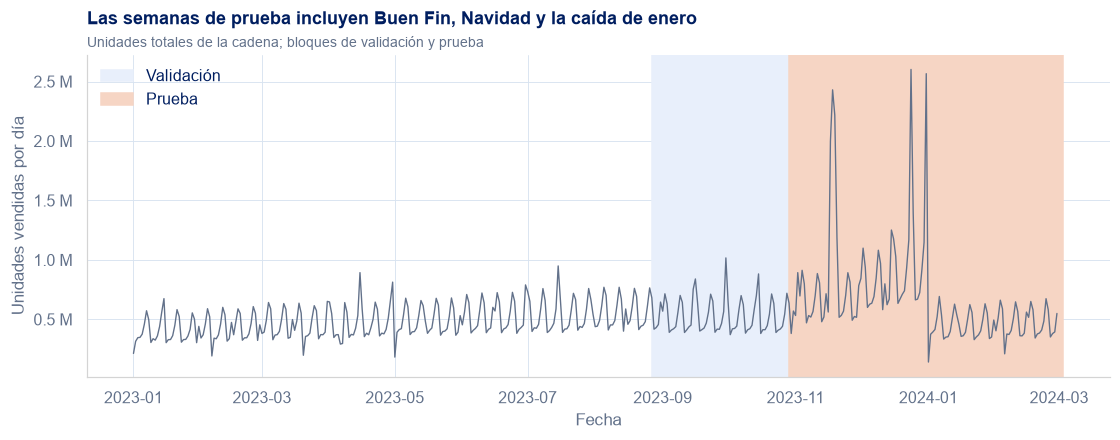

In [2]:
diaria = panel.groupby("date")["units_sold"].sum()
val = pd.date_range(*cfg["validation_origins"], freq="W-SUN")
test = pd.date_range(*cfg["test_origins"], freq="W-SUN")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axvspan(val[0], val[-1] + pd.Timedelta(days=7), color=viz.SEQ_BLUE[0], label="Validación")
ax.axvspan(test[0], test[-1] + pd.Timedelta(days=7), color="#f6d5c4", label="Prueba")
sns.lineplot(x=diaria.index, y=diaria.values, color=viz.INK_2, linewidth=0.9, ax=ax)
viz.fmt_millions(ax, decimals=1)
ax.set(xlabel="Fecha", ylabel="Unidades vendidas por día")
ax.set_title("Las semanas de prueba incluyen Buen Fin, Navidad y la caída de enero")
viz.subtitle(ax, "Unidades totales de la cadena; bloques de validación y prueba")
ax.legend(loc="upper left")
plt.show()

**Limitación importante.** Los datos empiezan en enero de 2023, así que el **Buen Fin y la
Navidad de 2023 son los primeros de la historia**: ningún modelo los vio antes. Esas semanas se
reportan por separado (sección 7). En producción, con un año más de historia, un rezago de 364
días los capturaría; mientras tanto, la práctica estándar es un ajuste manual del planeador para
esos eventos.

## 3 · Modelos que se comparan

Una escalera de complejidad. Cada modelo tiene que ganarse su lugar contra el anterior:

| Nivel | Modelo | Qué representa |
|---|---|---|
| 0 | **Sistema actual** | Promedio de los últimos 7 días, la misma lógica de `replenishment_signal` pero **sin ver el futuro** |
| 0 | **Naive estacional** | Lo que se vendió el mismo día de la semana pasada |
| 1 | **Holt-Winters** | Serie de tiempo clásica, un modelo por serie: nivel, tendencia y ciclo semanal |
| 2 | **Regresión Poisson** | Modelo lineal (log) con las mismas variables que los árboles; interpretable |
| 3 | **LightGBM** | Boosting global: aprende de las 480 series a la vez e interacciones como evento × formato |
| 3 | **XGBoost** | Boosting global, otra implementación; confirma si la ganancia es del método o de la librería |

**Métricas.**
- **WAPE** = Σ|error| / Σ venta real. Se lee como "% de la demanda que se pronosticó mal". No
  explota con ventas pequeñas, a diferencia del MAPE, y permite sumar series de distinto tamaño.
- **Sesgo** = Σ error / Σ venta real. Positivo: se pide de más (sobreinventario). Negativo: se
  pide de menos (venta perdida).

**Regla de elección** (fijada antes de ver la prueba): gana el menor WAPE en prueba, salvo que un
modelo más simple empate estadísticamente (bootstrap por tienda; sección 7), en cuyo caso gana el
simple. Después se **verifica** que el elegido no empeore en ningún segmento (sección 9) y su
impacto en MXN (sección 10).

## 4 · Variables (feature engineering)

Las variables se construyen en `src/retail_analytics/features.py`. Están probadas con un test
de fuga: si se alteran las ventas posteriores a una fecha, ninguna variable anterior cambia.

In [3]:
desc = {
    "calendar": "Día de la semana y del mes, mes, fin de semana, quincena, festivo y su nombre, Buen Fin, temporada navideña, Semana Santa",
    "lags": "Unidades de hace 7, 14, 21 y 28 días; si hace 7 días fue festivo o quincena",
    "rolling": "Promedio de 7 y 28 días, mediana y desviación de 28 días (todas terminan 7 días antes); promedio del mismo día en las últimas 4 semanas",
    "store_traffic": "Transacciones diarias promedio de la tienda (todas las categorías) en los 7 días que terminan 7 días antes",
    "store": "Formato, región, nivel socioeconómico, m², cajas, farmacia, gasolinera",
    "category": "Categoría",
    "promotion": "Promoción planeada para ese día",
}
pd.DataFrame({"variables": {g: len(c) for g, c in FEATURE_GROUPS.items()}, "contenido": desc}).rename_axis("grupo")

,variables,contenido
grupo,,
calendar,10,"Día de la semana y del mes, mes, fin de semana..."
lags,6,"Unidades de hace 7, 14, 21 y 28 días; si hace ..."
rolling,5,"Promedio de 7 y 28 días, mediana y desviación ..."
store_traffic,1,Transacciones diarias promedio de la tienda (t...
store,7,"Formato, región, nivel socioeconómico, m², caj..."
category,1,Categoría
promotion,1,Promoción planeada para ese día


## 5 · Selección de variables

Se hace **por grupos** y solo en validación. Se entrena LightGBM con todas las variables y luego
quitando un grupo a la vez. Si quitar un grupo no empeora el WAPE de validación en al menos 0.1
puntos, el grupo sale: no aporta lo suficiente para justificar su complejidad.

Se eligió por grupos y no variable por variable porque las variables de un grupo están muy
correlacionadas (por ejemplo, los rezagos entre sí). Quitarlas una por una subestima su aporte
conjunto.

In [4]:
abl = ablation.copy()
abl["cambio (puntos de WAPE)"] = abl["cambio_vs_completo"] * 100
abl[["grupo_quitado", "wape", "cambio (puntos de WAPE)", "se_queda"]].style.format(
    {"wape": "{:.2%}", "cambio (puntos de WAPE)": "{:+.2f}"}, na_rep="-"
)

,grupo_quitado,wape,cambio (puntos de WAPE),se_queda
0,(ninguno),24.39%,+0.00,-
1,calendar,26.68%,+2.29,True
2,lags,24.39%,-0.00,False
3,rolling,24.58%,+0.19,True
4,store_traffic,24.48%,+0.09,False
5,store,24.37%,-0.02,False
6,category,24.50%,+0.11,True
7,promotion,24.38%,-0.01,False


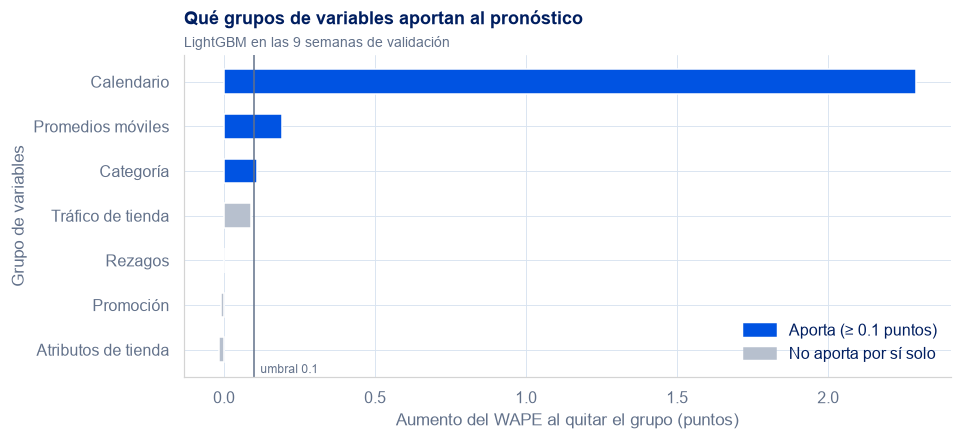

In [5]:
from matplotlib.patches import Patch

NOMBRE_GRUPO = {"calendar": "Calendario", "lags": "Rezagos", "rolling": "Promedios móviles", "store_traffic": "Tráfico de tienda",
                "store": "Atributos de tienda", "category": "Categoría", "promotion": "Promoción"}
a = abl[abl["grupo_quitado"] != "(ninguno)"].sort_values("cambio (puntos de WAPE)")
a["grupo"] = a["grupo_quitado"].map(NOMBRE_GRUPO)
a["color"] = np.where(a["se_queda"].astype(bool), viz.PRIMARY_BLUE, viz.MUTED)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(a["grupo"], a["cambio (puntos de WAPE)"], color=a["color"], height=0.55)
ax.axvline(0.1, color=viz.INK_2, linewidth=1)
ax.text(0.12, -0.45, "umbral 0.1", color=viz.INK_2, fontsize=8, va="center")
ax.set(xlabel="Aumento del WAPE al quitar el grupo (puntos)", ylabel="Grupo de variables")
ax.set_title("Qué grupos de variables aportan al pronóstico")
viz.subtitle(ax, "LightGBM en las 9 semanas de validación")
ax.legend(handles=[Patch(color=viz.PRIMARY_BLUE, label="Aporta (≥ 0.1 puntos)"), Patch(color=viz.MUTED, label="No aporta por sí solo")],
          loc="lower right", frameon=False)
plt.show()

**Verificación del conjunto final.** Quitar grupos uno por uno puede eliminar juntos dos grupos
que se sustituyen entre sí (cada uno parece inútil mientras el otro está). Por eso el conjunto
candidato se vuelve a evaluar contra el completo antes de aceptarlo:

In [6]:
check = pd.read_csv(out / "validation_selection_check.csv")
check.style.format({"wape": "{:.2%}"}).hide(axis="index")

conjunto,wape,grupos
completo,24.39%,"calendar, lags, rolling, store_traffic, store, category, promotion"
candidato (ablación),24.52%,"calendar, rolling, category"
elegido,24.39%,"calendar, lags, rolling, store_traffic, store, category, promotion"


> **Decisión.** La ablación sugería quedarse solo con calendario, promedios móviles y categoría: los demás grupos no aportaban por separado. Pero ese conjunto reducido empeoró el WAPE de validación en 0.13 puntos frente al completo, más que el umbral de 0.1. Los grupos que "no aportaban" eran **redundantes entre sí, no inútiles**, así que **se conservan las 31 variables**.
>
> Dos lecturas de negocio: el **calendario** es por mucho lo más importante (quitarlo empeora 2.3 puntos), y la **promoción no aporta nada** al pronóstico, consistente con el notebook 03.

## 6 · Ajuste de hiperparámetros

Rejillas pequeñas, evaluadas solo en validación. No se busca exprimir el último décimo: con
este volumen de datos, una rejilla pequeña alrededor de valores estándar es suficiente y reduce
el riesgo de sobreajustar a las semanas de validación.

In [7]:
mejor = tuning.loc[tuning.groupby("modelo")["wape"].idxmin()].set_index("modelo")
mejor["configuraciones probadas"] = tuning.groupby("modelo").size()
mejor[["parametros", "wape", "configuraciones probadas"]].style.format({"wape": "{:.2%}"})

,parametros,wape,configuraciones probadas
modelo,,,
lightgbm,"{""objective"": ""tweedie"", ""num_leaves"": 31, ""n_estimators"": 600}",24.17%,8
poisson_glm,"{""alpha"": 0.0001}",24.81%,2
xgboost,"{""max_depth"": 6, ""n_estimators"": 600}",24.25%,4


## 7 · Resultados en las semanas de prueba

Primera y única vez que se usan las 18 semanas de prueba.

In [8]:
res = ev.score(preds, by=["model"]).reindex(ORDEN)
base = res.loc["sistema_actual", "wape"]
res["mejora vs sistema actual"] = 1 - res["wape"] / base
res.index = res.index.map(NOMBRES)
res[["wape", "bias", "mejora vs sistema actual"]].style.format(
    {"wape": "{:.1%}", "bias": "{:+.1%}", "mejora vs sistema actual": "{:+.1%}"}
)

,wape,bias,mejora vs sistema actual
model,,,
Sistema actual (promedio 7 días),45.2%,+0.6%,+0.0%
Naive estacional,47.1%,+0.2%,-4.2%
Holt-Winters,42.8%,+1.0%,+5.4%
Regresión Poisson,37.2%,-4.6%,+17.9%
LightGBM,34.9%,-3.8%,+22.7%
XGBoost,35.7%,-1.1%,+21.1%


In [9]:
preds["tipo de día"] = np.select(
    [preds["is_buen_fin"], preds["is_navidad_season"]],
    ["Buen Fin (sin historia)", "Temporada navideña (sin historia)"],
    default="Días normales",
)
por_tipo = ev.score(preds, by=["tipo de día", "model"])["wape"].unstack("tipo de día").reindex(ORDEN)
por_tipo.index = por_tipo.index.map(NOMBRES)
por_tipo.style.format("{:.1%}")

tipo de día,Buen Fin (sin historia),Días normales,Temporada navideña (sin historia)
model,,,
Sistema actual (promedio 7 días),64.6%,37.1%,58.4%
Naive estacional,63.3%,44.4%,48.1%
Holt-Winters,61.9%,37.0%,50.3%
Regresión Poisson,64.9%,30.2%,44.3%
LightGBM,63.9%,27.6%,42.8%
XGBoost,59.2%,29.7%,42.0%


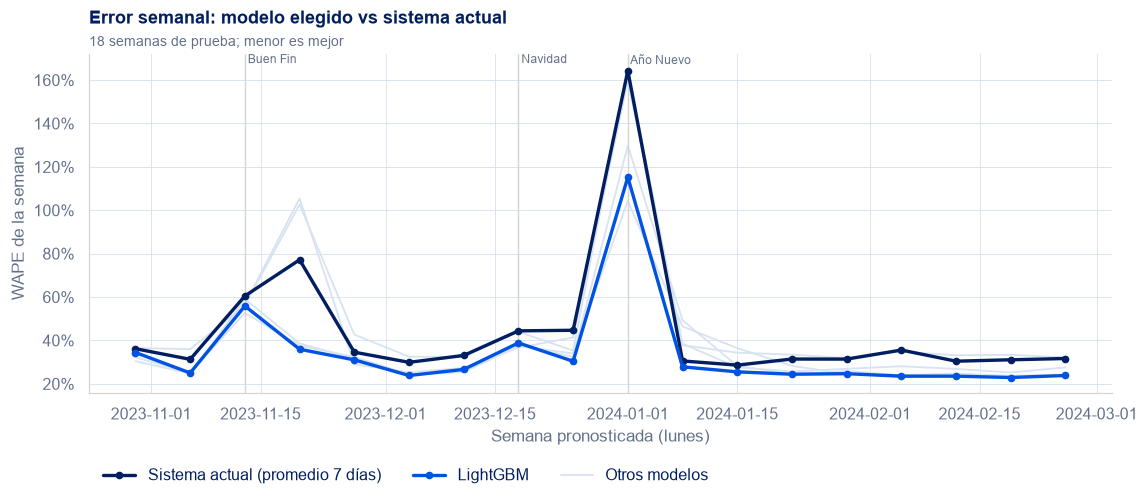

In [10]:
semanal = ev.score(preds, by=["origin", "model"]).reset_index()
semanal["semana"] = semanal["origin"] + pd.Timedelta(days=1)
destacar = {"sistema_actual": viz.SERIES[1], setup.get("ganador", "lightgbm"): viz.SERIES[0]}
fig, ax = plt.subplots(figsize=(12, 4))
for m in ORDEN:
    d = semanal[semanal["model"] == m]
    color = destacar.get(m, viz.GRID)
    ax.plot(d["semana"], d["wape"], color=color, linewidth=2.2 if m in destacar else 1.2,
            marker="o" if m in destacar else None, markersize=4, label=NOMBRES[m] if m in destacar else None, zorder=3 if m in destacar else 1)
ax.plot([], [], color=viz.GRID, linewidth=1.2, label="Otros modelos")
for d, txt in [("2023-11-13", "Buen Fin"), ("2023-12-18", "Navidad"), ("2024-01-01", "Año Nuevo")]:
    ax.axvline(pd.Timestamp(d), color=viz.AXIS, linewidth=0.9)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1], f" {txt}", color=viz.INK_2, fontsize=8, va="top")
viz.fmt_pct(ax)
ax.set(xlabel="Semana pronosticada (lunes)", ylabel="WAPE de la semana")
ax.set_title("Error semanal: modelo elegido vs sistema actual")
viz.subtitle(ax, "18 semanas de prueba; menor es mejor")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=3)
plt.show()

> **Conclusión.** Todos los modelos aprendidos superan al sistema actual; LightGBM lo hace por más margen (23% menos error). Por tipo de día:
>
> - **Días normales:** 27.6% vs 37.1% (−26%). Aquí el modelo tiene historia para aprender.
> - **Temporada navideña:** 42.8% vs 58.4% (−27%). Aunque es la primera Navidad completa en los datos, el modelo aprovecha el calendario (Nochebuena, Fin de Año) y la caída de enero.
> - **Buen Fin:** 63.9% vs 64.6%, prácticamente igual. Ningún modelo había visto un Buen Fin; esas semanas requieren ajuste manual del planeador hasta que exista un año de historia.
>
> El sesgo de LightGBM es −3.8%: pronostica ligeramente de menos, sobre todo en los picos que no conocía.

### Elección del modelo

La regla se fijó antes de ver la prueba: gana el menor WAPE, **salvo que un modelo más simple
empate en la práctica**. Para decidir si dos modelos empatan se usa un **bootstrap por tienda**:
se remuestrean las 80 tiendas 2,000 veces y se calcula la diferencia de WAPE contra el mejor
modelo. Si el intervalo del 95% incluye el cero, la diferencia no es distinguible del azar y gana
el más simple. Se remuestrean tiendas completas porque las series de una misma tienda comparten
choques.

In [11]:
sel = pd.read_csv(out / "test_model_selection.csv", index_col="model")
sel.index = sel.index.map(NOMBRES)
print(f"Modelo elegido: {NOMBRES[setup['ganador']]}")
sel.rename(columns={"diff": "diferencia vs mejor", "lo": "IC 95% inf", "hi": "IC 95% sup"}).style.format(
    {"wape": "{:.2%}", "diferencia vs mejor": "{:+.2%}", "IC 95% inf": "{:+.2%}", "IC 95% sup": "{:+.2%}"}
)

Modelo elegido: LightGBM


,wape,diferencia vs mejor,IC 95% inf,IC 95% sup,empate_con_mejor
model,,,,,
Sistema actual (promedio 7 días),45.23%,+10.29%,+9.87%,+10.68%,False
Naive estacional,47.11%,+12.17%,+11.74%,+12.57%,False
Holt-Winters,42.77%,+7.83%,+7.13%,+8.58%,False
Regresión Poisson,37.15%,+2.21%,+1.88%,+2.52%,False
LightGBM,34.94%,+0.00%,+0.00%,+0.00%,True
XGBoost,35.69%,+0.75%,+0.53%,+0.96%,False


> **Decisión: LightGBM.** Gana por menor WAPE y ningún modelo más simple empata: la regresión Poisson queda 2.2 puntos atrás (IC 95%: 1.9 a 2.5) y XGBoost 0.75 puntos (IC 95%: 0.53 a 0.96). Ningún intervalo incluye el cero, así que las diferencias no son azar.
>
> Por qué tiene sentido que gane: un modelo global aprende de las 480 series a la vez los efectos de calendario (que la ablación mostró que son lo más importante) y sus interacciones con formato y categoría, que Holt-Winters no puede usar y la regresión Poisson solo captura de forma aditiva en logaritmo.

## 8 · ¿Cuánto margen de mejora queda?

Un WAPE de ~35% (28% en días normales) puede parecer alto. Para saber si es mucho o poco hay que compararlo con el
error **inevitable**. Se construyen dos "oráculos" que hacen trampa a propósito: usan datos del
futuro.

- **Oráculo 1:** conoce el promedio real de cada tienda × categoría × mes × día de la semana.
- **Oráculo 2:** además conoce cuánta gente entró a cada tienda ese día.

Lo que ni siquiera ellos aciertan es ruido diario que ningún modelo puede anticipar.

In [12]:
p = panel[panel["units_sold"].notna()].copy()
o1 = p.groupby(["store_id", "category", "year", "month", "day_of_week"])["units_sold"].transform("mean")
choque = (np.log(p["units_sold"]) - np.log(o1)).groupby([p["store_id"], p["date"]]).transform("mean")
o2 = o1 * np.exp(choque)
en_prueba = p["date"].between(test[0] + pd.Timedelta(days=1), test[-1] + pd.Timedelta(days=7))
normales = en_prueba & ~p["is_buen_fin"] & ~p["is_navidad_season"]
piso = pd.DataFrame(
    {
        "WAPE días normales de prueba": [ev.wape(p.loc[normales, "units_sold"], o[normales]) for o in (o1, o2)],
    },
    index=["Oráculo 1: perfil mensual real", "Oráculo 2: + afluencia real del día"],
)
modelos_normales = por_tipo["Días normales"].rename("WAPE días normales de prueba").to_frame()
pd.concat([piso, modelos_normales]).style.format("{:.1%}")

,WAPE días normales de prueba
Oráculo 1: perfil mensual real,27.3%
Oráculo 2: + afluencia real del día,18.4%
Sistema actual (promedio 7 días),37.1%
Naive estacional,44.4%
Holt-Winters,37.0%
Regresión Poisson,30.2%
LightGBM,27.6%
XGBoost,29.7%


> **Conclusión.** En días normales LightGBM (27.6%) está prácticamente al nivel del oráculo 1 (27.3%), que **conoce de antemano** el perfil real de cada serie. Lo que separa al modelo del oráculo 2 (18.4%) es la afluencia de cada tienda ese día, que no se puede saber con una semana de anticipación. **Queda poco margen de mejora con estos datos**; la siguiente ganancia vendría de nueva información (por ejemplo, un año más de historia para los eventos, o datos de tráfico en tiempo real).

## 9 · Desempeño por segmento

Un buen promedio puede esconder segmentos donde el modelo empeora. Se compara el modelo elegido
contra el sistema actual en cada formato, región, nivel socioeconómico y categoría.

In [13]:
ganador = setup.get("ganador", "lightgbm")
filas = []
for seg in ["store_format", "region", "socioeconomic_level", "category"]:
    s = ev.score(preds[preds["model"].isin(["sistema_actual", ganador])], by=[seg, "model"])["wape"].unstack("model")
    s.index = [f"{seg}: {i}" for i in s.index]
    filas.append(s)
seg = pd.concat(filas)
seg["mejora"] = 1 - seg[ganador] / seg["sistema_actual"]
seg = seg.rename(columns={"sistema_actual": "Sistema actual", ganador: NOMBRES[ganador]})
seg.style.format("{:.1%}")

model,LightGBM,Sistema actual,mejora
store_format: Express,34.6%,43.0%,19.6%
store_format: Bodega,35.6%,45.7%,22.1%
store_format: Supercenter,34.4%,45.6%,24.5%
region: Centro,34.7%,45.3%,23.2%
region: Norte,34.7%,45.4%,23.6%
region: Occidente,34.6%,44.5%,22.3%
region: Oriente,35.5%,45.7%,22.5%
region: Sur,35.4%,45.5%,22.1%
socioeconomic_level: C,35.1%,45.1%,22.1%
socioeconomic_level: C+,35.1%,45.5%,23.0%


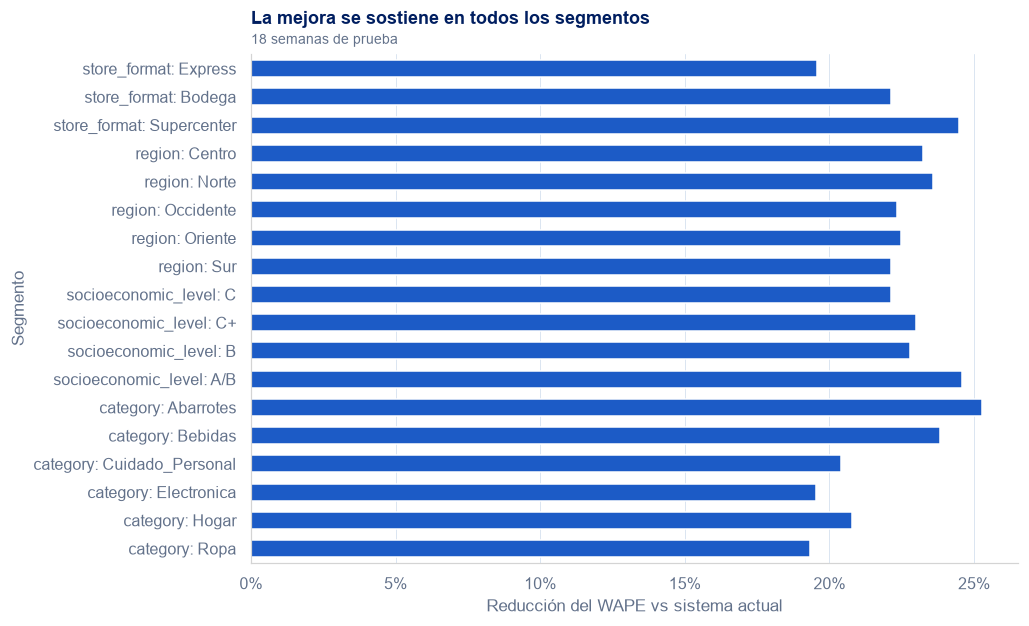

In [14]:
s = seg.reset_index().rename(columns={"index": "segmento"})
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=s, y="segmento", x="mejora", color=viz.SERIES[0], width=0.6, ax=ax)
viz.fmt_pct(ax, axis="x")
ax.set(xlabel="Reducción del WAPE vs sistema actual", ylabel="Segmento")
ax.set_title("La mejora se sostiene en todos los segmentos")
viz.subtitle(ax, "18 semanas de prueba")
plt.show()

> **Conclusión.** El modelo mejora entre 19% y 25% en **todos** los segmentos: no hay formato, región, nivel socioeconómico ni categoría donde convenga quedarse con el sistema actual. La mejora es algo menor en Electrónica, Ropa y Express, segmentos con menos volumen diario y por tanto más ruido relativo.

## 10 · Días normales vs festivos

El resultado global mezcla dos tipos de día muy distintos. En los **días normales** el modelo
tiene mucha historia; en los **festivos** depende de si ya vio ese festivo antes, y con datos
desde enero de 2023 casi ningún festivo de la prueba se había visto.

In [15]:
from retail_analytics.features import HOLIDAY_FAMILIES

cal = raw.calendar[["date", "holiday_name", "is_holiday"]]
pr = preds.drop(columns=["holiday_name"], errors="ignore").merge(cal.drop(columns="is_holiday"), on="date", how="left")
pr["tipo de día"] = np.where(pr["holiday_name"].notna(), "Festivo", "Día sin festivo")
t_dia = ev.score(pr[pr["model"].isin(["sistema_actual", ganador])], by=["tipo de día", "model"])["wape"].unstack("model")
t_dia["dias"] = pr[pr["model"] == ganador].groupby("tipo de día")["date"].nunique()
t_dia.rename(columns={"sistema_actual": "Sistema actual", ganador: NOMBRES[ganador]}).style.format({"Sistema actual": "{:.1%}", NOMBRES[ganador]: "{:.1%}"})

model,LightGBM,Sistema actual,dias
tipo de día,,,
Día sin festivo,28.4%,40.5%,112
Festivo,61.3%,64.3%,11


### Cada festivo se comporta distinto

Efecto de cada festivo sobre las unidades, frente al mismo día de la semana del mismo mes sin
festivo (descriptivo, con todos los datos):

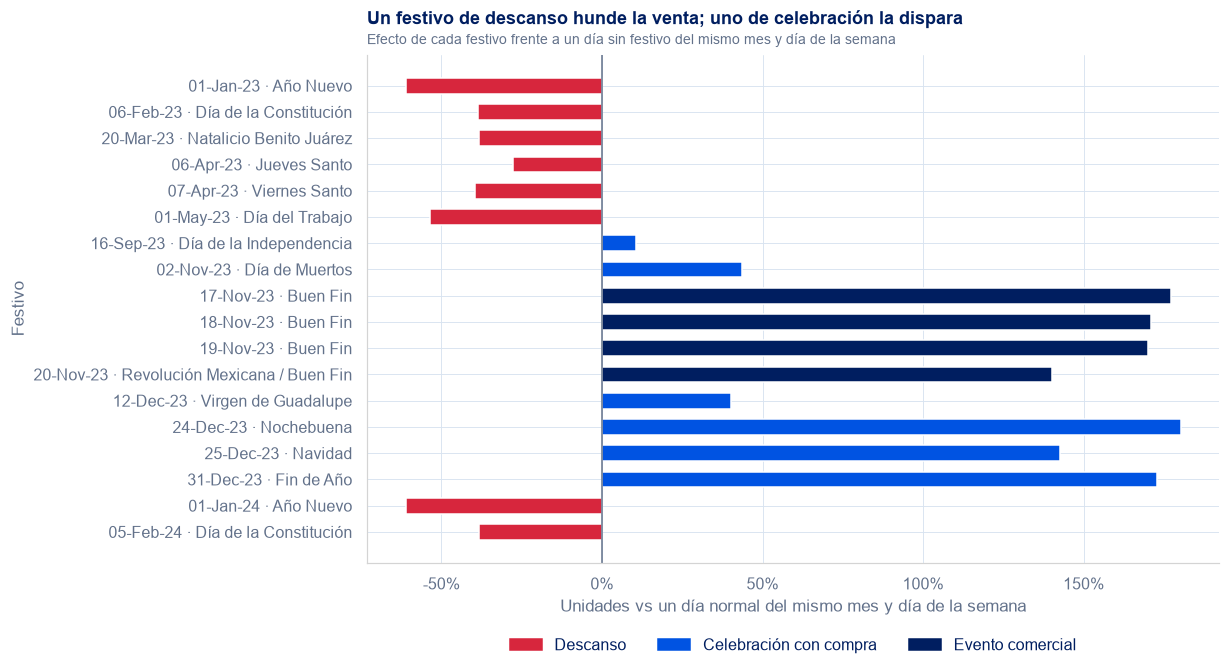

In [16]:
pp = panel[panel["units_sold"].notna()].copy()
pp["ym"] = pp["date"].dt.to_period("M")
base = pp[~pp["is_holiday"] & ~pp["is_navidad_season"]].groupby(["store_id", "category", "ym", "day_of_week"])["units_sold"].mean().rename("base")
pp = pp.join(base, on=["store_id", "category", "ym", "day_of_week"])
efecto = (pp[pp["is_holiday"]].assign(rel=lambda d: d["units_sold"] / d["base"] - 1)
          .groupby(["date", "holiday_name"])["rel"].mean().reset_index())
efecto["familia"] = efecto["holiday_name"].map(HOLIDAY_FAMILIES)
efecto["etiqueta"] = efecto["date"].dt.strftime("%d-%b-%y") + " · " + efecto["holiday_name"]
COL_FAM = {"descanso": viz.DIVERGING["neg"], "celebracion": viz.PRIMARY_BLUE, "evento_comercial": viz.NAVY}
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(efecto["etiqueta"], efecto["rel"], color=efecto["familia"].map(COL_FAM), height=0.6)
ax.axvline(0, color=viz.INK_2, linewidth=1)
ax.invert_yaxis()
viz.fmt_pct(ax, axis="x")
ax.set(xlabel="Unidades vs un día normal del mismo mes y día de la semana", ylabel="Festivo")
ax.set_title("Un festivo de descanso hunde la venta; uno de celebración la dispara")
viz.subtitle(ax, "Efecto de cada festivo frente a un día sin festivo del mismo mes y día de la semana")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COL_FAM["descanso"], label="Descanso"), Patch(color=COL_FAM["celebracion"], label="Celebración con compra"),
                   Patch(color=COL_FAM["evento_comercial"], label="Evento comercial")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()

- **Descanso** (puentes, Semana Santa, Día del Trabajo, Año Nuevo): la venta **cae 28% a 61%**.
- **Celebración con compra** (Independencia, Día de Muertos, Guadalupe, Nochebuena, Navidad, Fin
  de Año): la venta **sube 11% a 180%**.
- **Evento comercial** (Buen Fin): la venta **sube +140% a +177%**.

**Por qué el modelo falla en algunos festivos.** Antes de la prueba (febrero a septiembre) el
modelo vio 5 festivos de descanso, todos a la baja, y solo uno de celebración (Independencia,
+11%). Aprendió que "festivo = la venta cae" y lo aplicó a Día de Muertos, Guadalupe y Navidad,
que en realidad suben.

In [17]:
hol = cal[cal["is_holiday"] & (cal["date"] >= cfg["train_start"])]
filas = []
for (d, nombre), g in pr[pr["holiday_name"].notna()].groupby(["date", "holiday_name"]):
    origen = g["origin"].iloc[0]
    visto = ((hol["date"] <= origen) & (hol["holiday_name"] == nombre)).any()
    w = ev.score(g, by=["model"])["wape"]
    filas.append({"fecha": d.date(), "festivo": nombre, "familia": HOLIDAY_FAMILIES[nombre], "¿ya lo había visto?": "Sí" if visto else "No",
                  NOMBRES[ganador]: w[ganador], "Sistema actual": w["sistema_actual"]})
vistos = pd.DataFrame(filas)
vistos.style.format({NOMBRES[ganador]: "{:.1%}", "Sistema actual": "{:.1%}"}).hide(axis="index")

fecha,festivo,familia,¿ya lo había visto?,LightGBM,Sistema actual
2023-11-02,Día de Muertos,celebracion,No,64.6%,42.8%
2023-11-17,Buen Fin,evento_comercial,No,70.8%,67.7%
2023-11-18,Buen Fin,evento_comercial,No,64.6%,73.8%
2023-11-19,Buen Fin,evento_comercial,No,65.0%,71.0%
2023-11-20,Revolución Mexicana / Buen Fin,evento_comercial,No,48.7%,28.8%
2023-12-12,Virgen de Guadalupe,celebracion,No,40.5%,24.2%
2023-12-24,Nochebuena,celebracion,No,68.0%,66.9%
2023-12-25,Navidad,celebracion,No,44.3%,29.9%
2023-12-31,Fin de Año,celebracion,No,32.8%,58.4%
2024-01-01,Año Nuevo,descanso,No,628.6%,720.9%


> **Lectura.** El único festivo de la prueba que el modelo ya había visto (Día de la Constitución,
> que también cayó en febrero de 2023) lo pronostica con 25% de error contra 123% del sistema
> actual. En los festivos nuevos depende de la familia: acierta en Fin de Año (después de ver
> Nochebuena) y falla en los de celebración que llegan antes de haber visto alguno parecido.
> **Con un año de historia, cada festivo tendrá al menos un antecedente.**

### ¿Qué se puede hacer sin más historia? Familias de festivos (exploratorio)

Se agrega una variable con la **familia** de cada festivo (descanso, celebración con compra,
evento comercial), definida por lo que la gente hace ese día. Así, un festivo nunca visto toma el
efecto aprendido de otros de su familia en lugar del promedio de todos los festivos.

**Advertencia de rigor:** las familias se definieron después de ver los resultados de prueba, y en
validación (que solo tiene un festivo) el cambio no se puede evaluar. Por eso este resultado es
**exploratorio**: indica la dirección, pero no reemplaza la cifra oficial del modelo.

In [18]:
exp = pd.read_parquet(out / "exp_familias_festivos.parquet")
exp_t = exp[exp["periodo"] == "prueba"].drop(columns="periodo").merge(cal, on="date", how="left")
base_t = pr[pr["model"].isin([ganador, "sistema_actual"])][exp_t.columns.intersection(pr.columns)]
comp = pd.concat([base_t, exp_t], ignore_index=True)
comp["familia"] = comp["holiday_name"].map(HOLIDAY_FAMILIES).fillna("sin festivo")
NOMBRES_EXP = {**NOMBRES, "lightgbm_familias": "LightGBM + familias (exploratorio)"}
por_fam = ev.score(comp, by=["familia", "model"])["wape"].unstack("model")
por_fam.loc["TOTAL PRUEBA"] = ev.score(comp, by=["model"])["wape"]
por_fam = por_fam[["sistema_actual", ganador, "lightgbm_familias"]].rename(columns=NOMBRES_EXP)
por_fam.style.format("{:.1%}")

model,Sistema actual (promedio 7 días),LightGBM,LightGBM + familias (exploratorio)
familia,,,
celebracion,51.3%,50.0%,45.8%
descanso,363.0%,267.6%,206.5%
evento_comercial,64.6%,63.9%,59.5%
sin festivo,40.5%,28.4%,28.5%
TOTAL PRUEBA,45.2%,34.9%,33.9%


In [19]:
pf = ev.score(comp[comp["holiday_name"].notna()].assign(fecha=lambda d: d["date"].dt.strftime("%d-%b-%Y")), by=["date", "fecha", "holiday_name", "model"])["wape"].unstack("model").droplevel("date")
pf = pf[["sistema_actual", ganador, "lightgbm_familias"]].rename(columns=NOMBRES_EXP)
pf.style.format("{:.1%}")

,model,Sistema actual (promedio 7 días),LightGBM,LightGBM + familias (exploratorio)
fecha,holiday_name,,,
02-Nov-2023,Día de Muertos,42.8%,64.6%,59.0%
17-Nov-2023,Buen Fin,67.7%,70.8%,61.3%
18-Nov-2023,Buen Fin,73.8%,64.6%,61.9%
19-Nov-2023,Buen Fin,71.0%,65.0%,61.9%
20-Nov-2023,Revolución Mexicana / Buen Fin,28.8%,48.7%,46.9%
12-Dec-2023,Virgen de Guadalupe,24.2%,40.5%,30.7%
24-Dec-2023,Nochebuena,66.9%,68.0%,64.4%
25-Dec-2023,Navidad,29.9%,44.3%,39.0%
31-Dec-2023,Fin de Año,58.4%,32.8%,30.6%


> **Conclusión.** Agrupar los festivos por familia mejora el pronóstico en **los 11 festivos de la
> prueba** y baja el error total de 34.9% a 33.9%, sin cambiar los días sin festivo. Aun así, en
> Día de Muertos, Guadalupe, Navidad y Revolución sigue siendo peor que el sistema actual: dentro
> de una familia los festivos todavía difieren mucho (+11% a +180%).
>
> **Qué hacer sin más historia, en orden:**
>
> 1. **Ajuste del planeador por familia de festivo** en el primer año (práctica estándar).
> 2. **Incorporar las familias** al modelo y validarlas con los festivos de los próximos meses
>    antes de adoptarlas oficialmente.
> 3. **Usar referencias externas** del efecto de cada festivo (por ejemplo, la experiencia
>    comercial de años anteriores) como valor inicial, hasta que el modelo acumule su propia
>    historia.

## 11 · Impacto de negocio en MXN

**Simulación.** Cada domingo, cada tienda pide para cada categoría lo que dice el pronóstico de
la semana. Si la demanda real supera el pedido, la diferencia es **venta perdida**; si el pedido
supera la demanda, es **sobreinventario**. Ambas se valúan al precio de venta de esa semana.

Es una política simplificada e idéntica para todos los modelos, así que la comparación es justa.
No incluye inventario de seguridad ni costos de almacenaje (no hay datos de costo ni de
inventario); por eso se reporta **venta perdida** y **sobreinventario a precio de venta**, sin
convertirlos en utilidad.

In [20]:
imp = ev.inventory_impact(preds[["model", "origin", "store_id", "category", "date", "y_true", "y_pred"]], prices)
tot = imp.groupby("model")[["sales_mxn", "lost_mxn", "excess_mxn"]].sum().reindex(ORDEN)
tot["venta perdida (% de la venta)"] = tot["lost_mxn"] / tot["sales_mxn"]
tot["sobreinventario (% de la venta)"] = tot["excess_mxn"] / tot["sales_mxn"]
tot.index = tot.index.map(NOMBRES)
(tot[["lost_mxn", "excess_mxn", "venta perdida (% de la venta)", "sobreinventario (% de la venta)"]] / [1e6, 1e6, 1, 1]).rename(
    columns={"lost_mxn": "venta perdida (M MXN)", "excess_mxn": "sobreinventario (M MXN)"}
).style.format({"venta perdida (M MXN)": "{:,.0f}", "sobreinventario (M MXN)": "{:,.0f}",
                "venta perdida (% de la venta)": "{:.1%}", "sobreinventario (% de la venta)": "{:.1%}"})

,venta perdida (M MXN),sobreinventario (M MXN),venta perdida (% de la venta),sobreinventario (% de la venta)
model,,,,
Sistema actual (promedio 7 días),"1,610","1,801",13.3%,14.9%
Naive estacional,"1,616","1,752",13.4%,14.5%
Holt-Winters,"1,749","1,987",14.5%,16.5%
Regresión Poisson,"1,818","1,373",15.1%,11.4%
LightGBM,"1,506","1,194",12.5%,9.9%
XGBoost,"1,433","1,618",11.9%,13.4%


In [21]:
g = NOMBRES[ganador]
s_act = tot.loc[NOMBRES["sistema_actual"]]
s_gan = tot.loc[g]
semanas = imp["origin"].nunique()
resumen_mxn = pd.DataFrame(
    {
        "Sistema actual": [s_act["lost_mxn"], s_act["excess_mxn"]],
        g: [s_gan["lost_mxn"], s_gan["excess_mxn"]],
    },
    index=["Venta perdida", "Sobreinventario"],
) / 1e6
resumen_mxn["diferencia"] = resumen_mxn[g] - resumen_mxn["Sistema actual"]
print(f"Periodo de prueba: {semanas} semanas · venta real: {s_act['sales_mxn'] / 1e6:,.0f} M MXN")
resumen_mxn.style.format("{:+,.0f}" if False else "{:,.0f}")

Periodo de prueba: 18 semanas · venta real: 12,076 M MXN


,Sistema actual,LightGBM,diferencia
Venta perdida,"1,610","1,506",-104
Sobreinventario,"1,801","1,194",-607


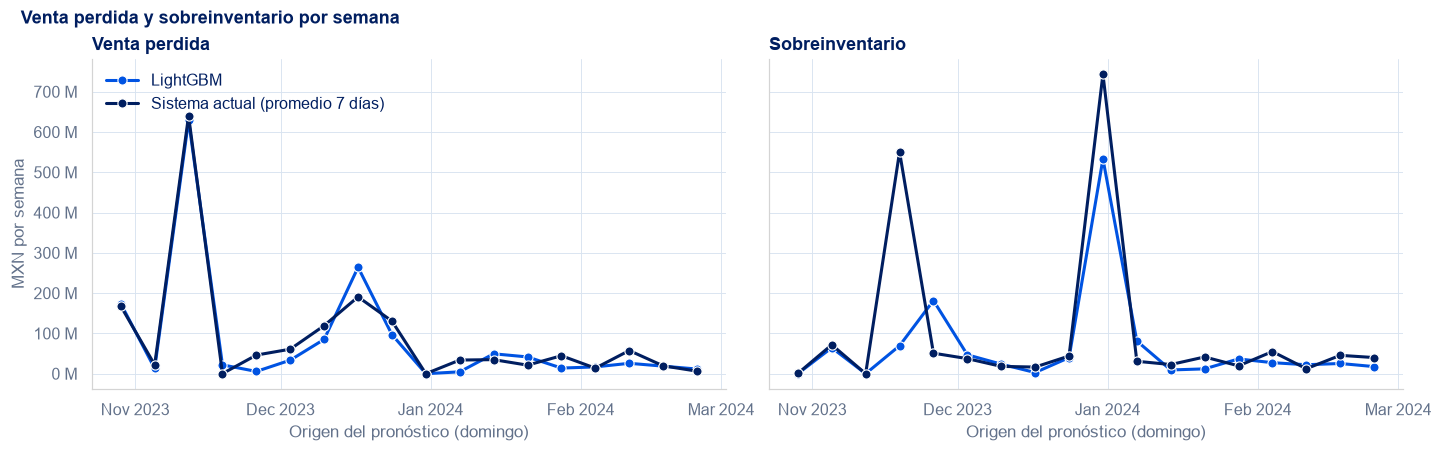

In [22]:
largo = imp[imp["model"].isin(["sistema_actual", ganador])].copy()
largo["Modelo"] = largo["model"].map(NOMBRES)
largo = largo.melt(id_vars=["origin", "Modelo"], value_vars=["lost_mxn", "excess_mxn"], var_name="tipo", value_name="mxn")
largo["tipo"] = largo["tipo"].map({"lost_mxn": "Venta perdida", "excess_mxn": "Sobreinventario"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, layout="constrained")
for ax, tipo in zip(axes, ["Venta perdida", "Sobreinventario"]):
    d = largo[largo["tipo"] == tipo]
    sns.lineplot(data=d, x="origin", y="mxn", hue="Modelo", palette={NOMBRES["sistema_actual"]: viz.SERIES[1], g: viz.SERIES[0]},
                 marker="o", ax=ax, legend=(tipo == "Venta perdida"))
    viz.fmt_millions(ax)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.set(xlabel="Origen del pronóstico (domingo)", ylabel="MXN por semana", title=tipo)
sns.move_legend(axes[0], "upper left", title="")
fig.suptitle("Venta perdida y sobreinventario por semana", x=0.01, ha="left", fontweight="bold")
plt.show()

> **Conclusión.** Pedir con el pronóstico reduce la venta perdida en **104 M MXN** (−6%) y el sobreinventario en **607 M MXN** (−34%) en 18 semanas, **711 M MXN** en total (−21%) sobre una venta de 12,076 M MXN.
>
> **Cómo leer las dos cifras.** La venta perdida es ingreso que no entra. El sobreinventario no es dinero perdido: es mercancía que no se vendió esa semana (capital inmovilizado, espacio y riesgo de merma). Por eso se reportan por separado.
>
> **Anualizado en proporción a la venta** (y no por número de semanas, porque la prueba incluye temporada alta): ~1,760 M MXN al año entre ambas, de los cuales ~260 M MXN son venta recuperada.
>
> **Dónde se concentra.** 482 de los 607 M MXN de sobreinventario evitado salen de una sola semana, la posterior al Buen Fin: el sistema actual, arrastrando el pico en su promedio, pidió 551 M MXN de más y el modelo 69 M. En las otras 17 semanas el ahorro en sobreinventario es de 125 M MXN, y la semana siguiente al Buen Fin el modelo sobrepidió más que el sistema actual (182 vs 51 M). El ahorro es real pero está concentrado en las semanas posteriores a los picos; el piloto con grupo control debe confirmarlo.
>
> XGBoost logra menos venta perdida, pero a cambio de mucho más sobreinventario; LightGBM equilibra mejor ambos errores.

## 12 · Conclusiones y limitaciones

**Conclusiones**

1. **LightGBM reemplaza al sistema actual con 23% menos error** en semanas que ningún modelo vio, y mejora en todos los segmentos.
2. **El valor es concreto:** 711 M MXN menos entre venta perdida y sobreinventario en 18 semanas de prueba.
3. **El modelo está cerca del límite de lo que estos datos permiten predecir**; la siguiente mejora requiere más historia o nueva información.

**Limitaciones**

- **Eventos sin historia:** el Buen Fin de 2023 fue el primero en los datos. Hasta tener un año de historia, el planeador debe ajustar manualmente esas semanas.
- **Impacto simulado:** no hay datos de inventario, agotados ni costos. La política de pedido es simple e igual para todos los modelos; un piloto con grupo control confirmaría el ahorro real.
- **Promoción como dato conocido:** se asume planeada; como no aporta al pronóstico, el supuesto no cambia los resultados.
- **Sesgo ligeramente negativo (−3.8%):** en operación conviene combinar el pronóstico con inventario de seguridad por categoría.

**Siguiente paso recomendado:** piloto de 90 días en un grupo de tiendas con grupo control, midiendo venta perdida y sobreinventario reales.